**Aim:** Identify sun groups of neuronal cells

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [1]:
import scez

Global seed set to 0


scanpy==1.9.1 anndata==0.8.0 umap==0.5.3 numpy==1.22.4 scipy==1.9.0 pandas==1.4.3 scikit-learn==1.1.2 statsmodels==0.13.2 python-igraph==0.9.11 pynndescent==0.5.7


In [2]:
import matplotlib.pyplot as plt

In [3]:
from utils import *

In [4]:
from upsetplot import from_contents, UpSet

## marker genes for neuronal/non-neuronal cells

In [5]:
cell_types = {
    "neuron":[
        "neuron main markers",
        "GABAergic",
        "glutamatergic",
        "D1 MSN",
        "D2 MSN (Ppp1r1b+ medial spiny neuron)",
        "D1H",
        "ICj"
    ]
}

In [6]:
# marker_genes
neuron_genes = {
    "GABAergic":["Gad1"],
    "glutamatergic":[
        "Grin3a",
        "Lrrtm2",
        "Slc1a1",
        "Slc1a2",
        "Gria1",
        # "Gria2",
        # "Grin1",
        # "Slc6a13",
        # "Slc7a11",
        # "Slc17a7",
        # "Slc17a6",
    ],
    "D1 MSN":['Tac1',"Pdyn"], # ,"Drd1a"
    # "D2 MSN":[ # (Ppp1r1b+ medial spiny neuron)
    #     "Penk",
    #     # "Drd2",
    #     "Adora2a"
    # ],
    # "D1H":[
        # "Nxph4",
    #     # "Tac2"
    # ],
    # "ICj":[
    #     # "Crtac1",
    #     "Rreb1"],
    # "patch marker":["Sema5b"],
    # "ventral striatum marker":["Crym"],
    # "medial Shell":[
    #     "Stard5",
    #     "Stra6"]
}

In [7]:
# new_markers = {
#     "Synaptic cell adhesion/transmission":[
#         "Nrxn1", "Nrxn2", "Nrxn3", "Lrrtm2", "Nlgn3","Nxph1", "Ncam1",'Ncam2', 'Homer2', 'Syt11',
#         'Gria3', 'Gria4', 'Grin2c', 'Camk2d'
#     ],
#     "Cell type markers": [
#         "Gad1", "Gad2", "Pcp4l1", "Sox11",
#     ],
#     "Solute carriers": [
#         "Slc6a6", "Slc38a11", "Slc6a11",
#     ],
#     "Neuromodulator receptor": [
#         "Drd1", "Drd2", "Penk", "Tac1", "Htr2c", "Adora1", 
#         "Npy1r", "Opcml", "Ntsr2", "Ntrk2",
#     ],
#     "Neurotrophic": [
#         "Epha5", "Ndnf", "Ntn4", "Sema7a", "Nnat",
#     ]
#     }

# new_markers = [
#     # 0: 
#     'Adora1', 'Lrrtm2', 'Ncam1', 'Ncam2', 'Nlgn3', 'Nrxn1', 'Nrxn2', 'Nxph1', 'Syt11',
#     # 2:
#     "Sema7a", "Ndnf","Pcp4l1", #(Pukinje cell)
#     # 3:
#     "Slc6a6", #(Chloride)
#     # 4:
#     "Nrxn1","Nrxn2","Grid2","Gria2","Opcml",
#     # 5:
#     "Sema7a",
#     # 6:
#     "Ncam2","Cadm1","Homer2", "Ncam1", "Itpr2", #(in neuron and astrocytes)
#     # 7:
#     "Nrxn1","Epha5","Nxph1","Gria3","Grid2","Ncam2",
#     # 9:
#     "Nrxn3","Sox11","Nnat","Gad2",
#     # 10:
#     "Ntn4","Npy1r","Slc38a11",
#     # 12:
#     "Nrxn3","Gria2","Gad2","Tac1","Htr2c","Penk","Gad1","Drd1",
#     # 13:
#     "Cntn1","Ntrk2","Nxph1","Nrxn1","Gria3","Syt11","Nlgn3","Gria4",
#     # 14:
#     "Grin2c","Camk2d","Ntsr2","Ntrk2",
#     # 15:
#     "Penk",
#     # 16:
#     "Drd2","Drd1",
#     # 17:
#     "Ntsr2","Slc6a11"
# ]


new_markers = [
    # 0: many 	
    "Nrxn1","Nxph1","Syt11","Nrxn2","Adora1","Lrrtm2","Nrxn2","Nlgn3","Ncam1","Ncam2",
    # 2: some
    "Ndnf","Pcp4l1", # (Pukinje cell)
    "Sema7a",
    # 3: some
    "Slc6a6", #(Chloride)
    # 4: many many
    "Nrxn1","Nrxn2","Grid2","Gria2","Opcml",
    # 5: some
    "Sema7a",
    # 6: many
    "Homer2","Ncam1","Itpr2", # (in neuron and astrocytes)
    "Wasf1","Ncam2","Cadm1",
    # 7: many 
    "Nrxn1","Epha5","Nxph1","Gria3","Grid2","Ncam2","Nrg3",
    # 8: some 
    "Vamp5",
    # 9: some
    "Nrxn3","Sox11","Nnat","Gad2",
    # 10: some
    "Ntn4","Npy1r","Slc38a11","Olfr558",
    # 12: many
    "Nrxn3","Gria2","Gad2","Tac1","Htr2c","Penk","Gad1","Drd1",
    # 13: many
    "Cntn1","Ntrk2","Nxph1","Nrxn1","Gria3","Syt11","Nlgn3","Gria4",
    # 14: many
    # "Grin2c",
    "Camk2d","Ntsr2","Ntrk2",
    # # 15: some
    # "Penk",
    # # 16: some
    # "Drd2","Drd1",
    # 17: some
    "Ntsr2","Slc6a11",
    "Snap25"
    
]

In [8]:
# ax = add_marker_feature(adata_neuron,marker='Snap25',marker_name='Snap25 label',clusters_name='leiden_neuron')

# plt.savefig('celltyping/percent_in_leiden_neuron_Snap25.pdf')

## Load data 
`adata` -> neuronal sub population; clustered

In [5]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron = sc.read_h5ad(results_file)

In [6]:
adata_neuron.layers['scaled'] = sc.pp.scale(adata_neuron, copy=True).X

In [7]:
adata_neuron

AnnData object with n_obs × n_vars = 12663 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Sox11 label', 'TdT label', 'label', 'leiden_neuron'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'leiden', 'leiden_neuron_colors', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts', 'scvi_normalized', 'scaled'
    obsp: 'connectivities', 'distances'

In [12]:
# adata_neuron[(adata_neuron.obs.leiden_neuron == '1') | (adata_neuron.obs.leiden_neuron == '11')]

In [ ]:
ax = sc.pl.dotplot(
    adata_neuron,
    new_markers,
    groupby=['leiden_neuron'],
    # swap_axes=True,
    dendrogram=True,
    # colorbar_title='mean z-score',
    # show_gene_labels=True,
    layer='scaled',
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'neuron_new_markers'
    # return_fig=True
)
# ax.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()
# !mv -v figures/dotplot_neuron_new_markers.pdf celltyping/neuron_new_markers_dotplot_v3.pdf
# !mv -v figures/heatmapneuron_new_markers.pdf celltyping/neuron_new_markers_heatmap_v3.pdf


#### Scale

In [14]:
adata_neuron.layers['scaled'] = sc.pp.scale(adata_neuron, copy=True).X

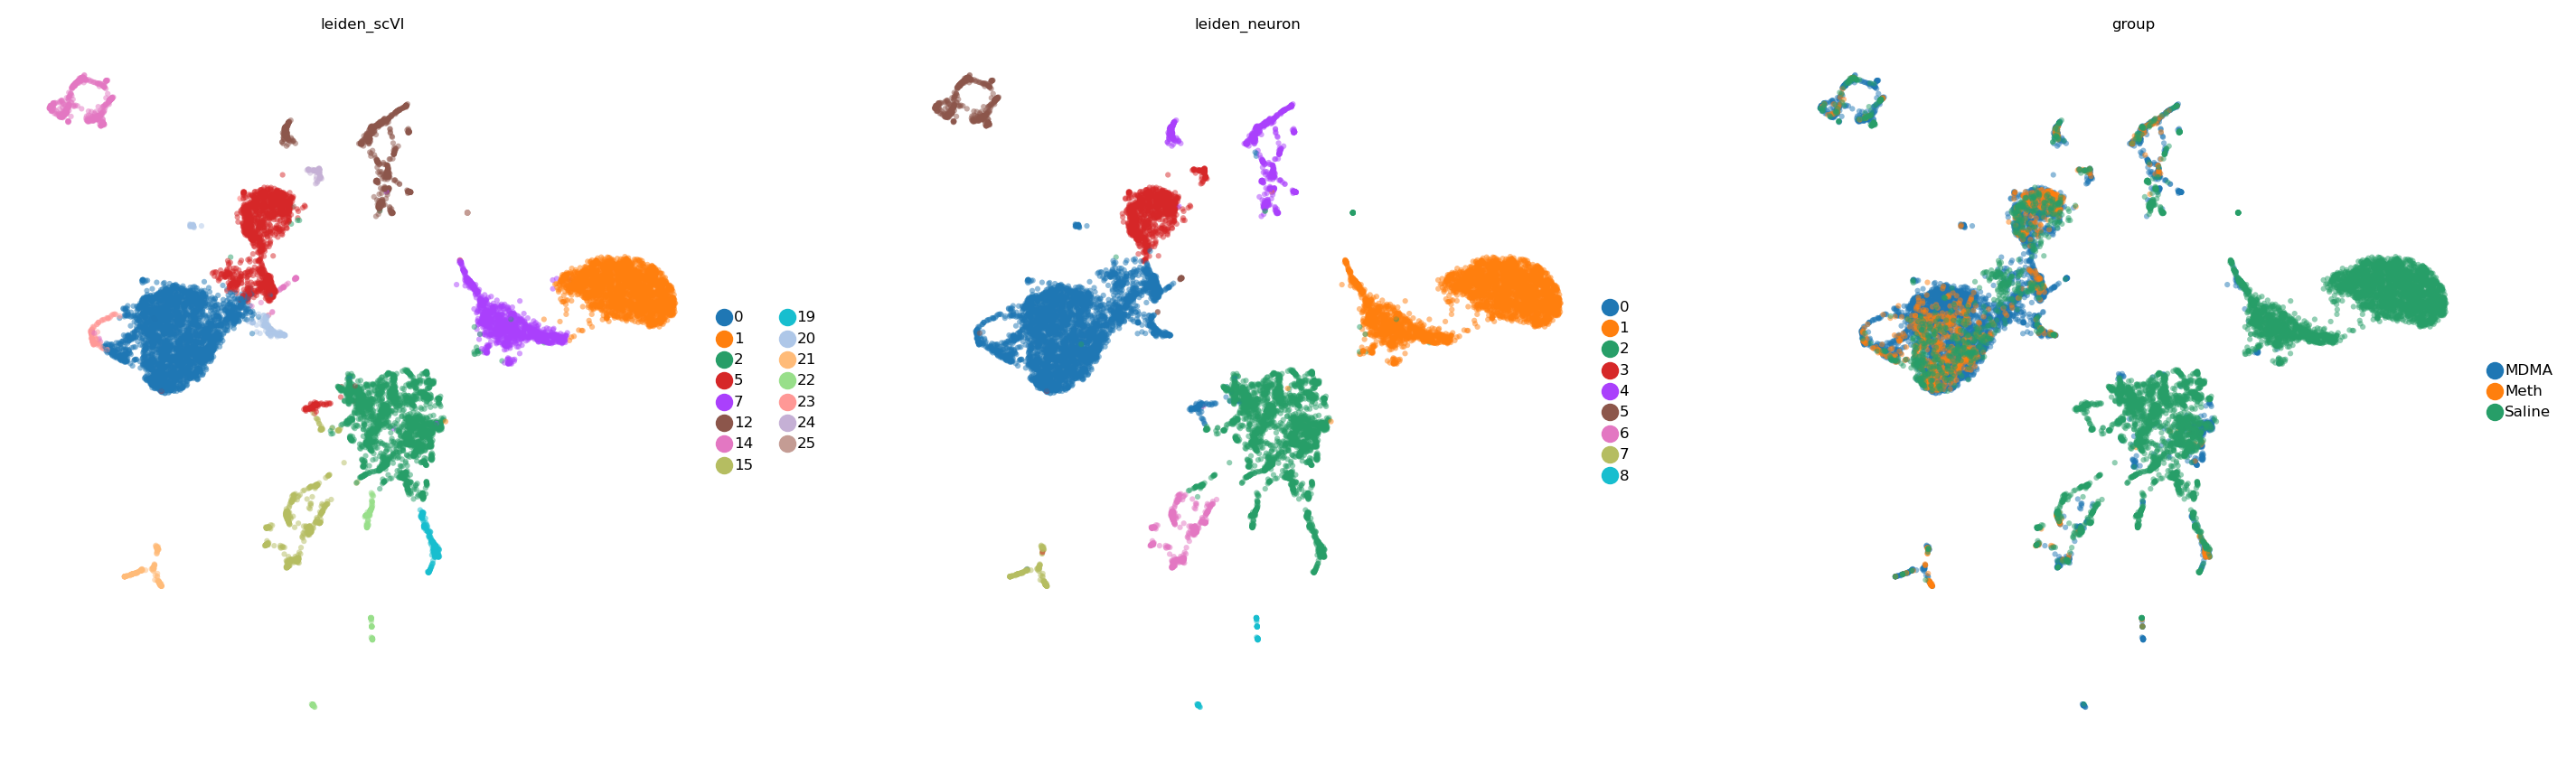

‘figures/umap_neuron.pdf’ -> ‘celltyping/neuron_umap.pdf’


In [15]:
sc.pl.umap(
    adata_neuron,
    color=[
        # "Snap25","Sox11",
        # "Gad1", # (GABAergic marker) 
        # # "Slc17a6", "Slc17a7", # glutamatergic marker
        # "Resp18", # interneuron marker
        # "Ppp1r1b",# MSN marker 
        # "Ptgds","Dlx1",
        
        "leiden_scVI",
        'leiden_neuron',
        'group',
    ],
    vmax=1,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=20,
    layer='scaled',
    # legend_loc='on data',
    # add_outline=0.1
    save = '_neuron'
)

!mv -v figures/umap_neuron.pdf celltyping/neuron_umap.pdf

In [16]:
# sc.pl.umap(
#     adata_neuron,
#     color=['Snap25','Sox11','Grin3a','Apod',#'Gria1',
#            'Gt(ROSA)26Sor',
#            'group',"leiden_scVI",'leiden_neuron'],
#     vmax=1,
#     vmin=0,
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=10,
#     # legend_loc='on data',
#     # add_outline=0.1
# )

In [17]:
# sc.pl.umap(
#     adata_neuron,
#     color=[
#         'group','leiden_neuron'
#     ],
#     vmin=0,vmax=1,
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=10,
#     # legend_loc='on data',
#     # add_outline=0.1
# )

### Conditions within sub-clusters

In [ ]:
sc.pl.umap(
    adata_neuron,
    color=[
        'group','leiden_neuron'
    ],
    vmin=0,vmax=1,
    color_map="Reds",
    frameon=False,alpha=0.3,size=40,
    legend_loc='on data',
    # add_outline=0.1
)

In [ ]:
df = pd.DataFrame(adata_neuron.obs.groupby(['group','leiden_neuron']).size()).reset_index().pivot(
    index='group', columns='leiden_neuron', values=0
).T

ax = df.plot.bar(stacked=True,rot=0,figsize=(3,2),width=0.9,fontsize=5)

ax.patch.set_facecolor('white')
ax.set_ylabel('# of cells',fontsize=8)
ax.set_xlabel('leiden_neuron',fontsize=8)
ax.grid(False)
ax.set_yscale('log')

plt.legend(loc='upper right', 
           # bbox_to_anchor=(1.2, 0.5),
           fontsize=5)
plt.show()

In [ ]:
df = pd.DataFrame(adata_neuron.obs.groupby(['group','leiden_neuron']).size()).reset_index().pivot(
    index='group', columns='leiden_neuron', values=0
).T
df = df.div(df.sum(axis=1), axis=0) * 100

ax = df.plot.bar(stacked=True,rot=0,figsize=(3,2),width=0.9,fontsize=5)

ax.patch.set_facecolor('white')
ax.set_ylabel('% of cells',fontsize=8)
ax.set_xlabel('leiden_neuron',fontsize=8)
ax.grid(False)
ax.get_legend().remove()

### Rank genes within sub-clusters

In [8]:
sc.tl.rank_genes_groups(
    adata_neuron, 'leiden_neuron', method='t-test'
)

In [9]:
def revert_upset_dataframe(up_data):
    return up_data.reset_index().set_index('id')

def get_intersection(up_data,which='all'):
    df = revert_upset_dataframe(up_data)
    if which == 'all':
        df = df[df.sum(axis=1) == 1]
        l = list()
        for col in df.columns:
            l.append((col, df.index[df[col]].tolist()))
            
        out = pd.DataFrame(l,columns=['cluster_vs_all','unique_ranked_genes'])
        out.unique_ranked_genes = out.unique_ranked_genes.str.join(',')
            
    else:
        out = pd.DataFrame(
        {
            'cluster_vs_all':which,
            'unique_ranked_genes':[','.join(df.index[df[which.split(',')].sum(axis=1)==2])]
        }
    )

    return out

In [10]:
ranked_neuron_clusters_full = rank_genes_to_df(
    adata_neuron, n = adata_neuron.var.shape[0]
)

In [11]:
ranked_neuron_clusters_full.to_csv('celltyping/ranked_neuron_clusters_full.csv')

In [25]:
# sc.tl.dendrogram(adata_neuron,'leiden_neuron')

In [26]:
# name = 'ranked_neuron_clusters_top'

# ax = sc.pl.dotplot(
#     adata_neuron, 
#     dict([(clust,genes.split(',')[:10]) for clust,genes in clusters_unique_ranked_genes.values]),
#     groupby=['leiden_neuron'], 
#     swap_axes=True, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     standard_scale="var",
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     save = name
# )

# !mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [27]:
# # name = 'ranked_neuron_clusters_top'

# ax = sc.pl.dotplot(
#     adata_neuron, 
# dict([(clust,genes.split(',')[:5]) for clust,genes in clusters_unique_ranked_genes.values
#       if clust in ['5_names,2_names','14_names,4_names']]),
#     groupby=['leiden_neuron'],
#     swap_axes=True, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     standard_scale="var",
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     # save = name
# )

# # !mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [28]:
# sc.tl.dendrogram(adata_neuron,'leiden_neuron')

In [29]:
# ax = sc.pl.dotplot(
#     adata_neuron, 
#     [gene for clust,genes in temp for gene in genes],# if clust in ['8_names','5_names','0_names',
#                                                                     # '1_names','2_names','4_names']], 
#     groupby=['leiden_neuron'], 
#     swap_axes=False, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     # layer='scaled', 
#     vmin=-4, vmax=4, cmap='RdBu_r',
#     # save = 'Snap25_neg'
# )

# # !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

rank_genes_groups_dotplot

In [ ]:
# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_neuron, 
#     groupby=['leiden_neuron'],
#     swap_axes=True,
#     n_genes=5,
#     layer='scaled',
#     values_to_plot='logfoldchanges', min_logfoldchange=3,
#     vmin=-4, vmax=4, cmap='RdBu_r',
# )

In [ ]:
# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_neuron, 
#     groupby=['leiden_neuron'],
#     n_genes=10,
#     values_to_plot='logfoldchanges', min_logfoldchange=3,
#     groups=['3','4'],
#     vmin=-4, vmax=4, cmap='RdBu_r',
# )

___

In [ ]:
ranked_neuron_clusters_top = ranked_neuron_clusters_full.filter(regex='names').iloc[:20,]

In [ ]:
ranked_neuron_clusters_top_rev = revert_upset_dataframe(
    from_contents(ranked_neuron_clusters_top)
)

In [ ]:
clusters_unique_ranked_genes = pd.concat([
    get_intersection(from_contents(ranked_neuron_clusters_top)),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='7_names,13_names,0_names'),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='13_names,9_names'),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='0_names,7_names'),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='14_names,4_names'),
    # get_intersection(from_contents(ranked_neuron_clusters_top),which='5_names,2_names'),
])

In [ ]:
# Create a Pandas Excel writer using XlsxWriter as the engine.
writer = pd.ExcelWriter('celltyping/ranked_neuron_clusters_top-v2.xlsx', engine='xlsxwriter')

# Write each dataframe to a different worksheet.
ranked_neuron_clusters_full.to_excel(writer, sheet_name='full')
clusters_unique_ranked_genes.set_index('cluster_vs_all').to_excel(writer, sheet_name='clusters_unique_ranked_genes')

# Close the Pandas Excel writer and output the Excel file.
writer.save()

In [29]:
# upset = UpSet(
#     from_contents(ranked_neuron_clusters_top),
#     # min_degree=2, 
#     subset_size='count',
#     min_subset_size=25, 
#     show_counts=True,
# ).plot()

# plt.savefig('celltyping/ranked_neuron_clusters_top_largest.pdf',font_size=10)

In [30]:
# upset = UpSet(
#     from_contents(ranked_neuron_clusters_top),
#     # min_degree=2, 
#     subset_size='count',
#     # min_subset_size=25, 
#     show_counts=True,
# ).plot()

# plt.savefig('celltyping/ranked_neuron_clusters_top_all.pdf',font_size=10)

___
`down` env

In [1]:
import blitzgsea as blitz

In [2]:
import pandas as pd 

In [9]:
ranked_neuron_clusters_full = pd.read_csv('celltyping/ranked_neuron_clusters_full.csv',index_col=0)

In [4]:
m5_gmt = blitz.enrichr.read_gmt(
    '/data_gilbert/home/aarab/Projects/pager/annotations/mouse/m5.all.v2022.1.Mm.symbols.gmt'
)

In [5]:
c5_gmt = blitz.enrichr.read_gmt(
    '/data_gilbert/home/aarab/Projects/pager/annotations/human/msigdb_v7.4_c5.go/c5.go.v7.4.symbols.gmt'
)

___

In [37]:
syngo = pd.read_csv('../synGOpy/syngo_ontologies_clean.txt',sep='\t').set_index('name').rename(columns={'hgnc_symbol':'genes'})

syngo_gmt = syngo.genes.str.split(', ').to_dict()

In [47]:
GSEA_res = {}

for i in range(0,ranked_neuron_clusters_full.shape[1],2):
    n = ranked_neuron_clusters_full.columns[i].split('_')[0]
    GSEA_res[f'{n}_clust'] = {}

    signature = ranked_neuron_clusters_full.iloc[:,[i,i+1]].copy()
    signature.iloc[:,0] = signature.iloc[:,0].str.upper()
    result = blitz.gsea(signature,syngo_gmt,max_size=50,verbose=True) # ,min_size=5
    result = result[(result.nes.gt(0))] #  & (result.fdr.le(0.2))
    GSEA_res[f'{n}_clust'] = {
        'signature':signature,
        'result':result,
    }

Enrichment : 100%|██████████| 293/293 [00:00<00:00, 1619.16it/s]


___

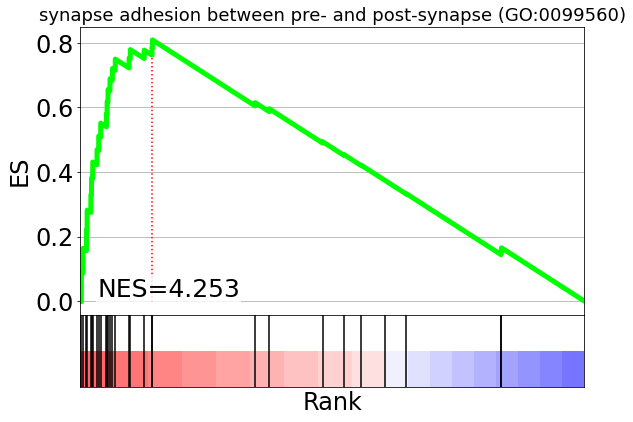

In [49]:
fig_compact = blitz.plot.running_sum(
    GSEA_res['0_clust']['signature'], 
    "synapse adhesion between pre- and post-synapse (GO:0099560)", 
    library=syngo_gmt, 
    result=GSEA_res['0_clust']['result'], 
    compact=True
)

fig_compact.savefig(
    'celltyping/ranked_neuron_clusters_GO_example_clust0_compact.pdf',
    bbox_inches='tight'
)

fig_compact
# fig = blitz.plot.running_sum(GSEA_res['0_clust']['signature'], "GOCC_INTRINSIC_COMPONENT_OF_SYNAPTIC_MEMBRANE", 
#                              library=m5_gmt, 
#                              result=GSEA_res['0_clust']['result'], 
#                              compact=False)

# fig.savefig(
#     'celltyping/ranked_neuron_clusters_GO_example_clust0.pdf',
#     bbox_inches='tight'
# )

In [50]:
writer = pd.ExcelWriter('celltyping/ranked_neuron_clusters_GO.xlsx', engine='xlsxwriter')
ranked_neuron_clusters_full.to_excel(writer, sheet_name='genes')

for clust in GSEA_res:
    GSEA_res[clust]['result'].to_excel(writer, sheet_name=clust)
writer.save()

### 
___

# 

In [92]:
!date

Wed Nov 23 00:04:58 PST 2022
